# Compare approaches

Reads **every result** in `results/` (old runs and new ones) and plots them together. This notebook never trains anything.

The plots and the summary table use the same metrics and the same style as the original comparison notebook (`06_compare_all_five_approaches`). They are saved to `results/` under the same file names as before:

| Output | Content |
|---|---|
| `comparison_summary.csv` | approach, evaluations, updates, virtual time, final accuracy, final loss |
| `comparison_accuracy_vs_updates_and_time.png` | accuracy vs client updates, and vs simulated time |
| `comparison_test_loss_vs_time.png` | test loss vs simulated time |
| `comparison_throughput_vs_time.png` | cumulative updates per second vs simulated time |

> **Important:** only results made with the **current** `settings.yaml` are compared; any others are listed and skipped. Set `INCLUDE_OTHER_SETTINGS = True` to include them anyway.

> **Note:** with several seeds, each point is the **average over seeds** of the n-th evaluation (same update count, mean time and mean accuracy).

## 1. Choose what to compare

`ORDER` sets the legend order and colours. Approaches not listed come after it, alphabetically.

In [1]:
RUNS = None                      # None = everything, or e.g. ["fedasync", "fedbuff", "sync_fedavg"]
INCLUDE_OTHER_SETTINGS = False
ORDER = ["sync_fedavg", "fedasync", "fedasync_staleness", "buffered_fedavg", "fedbuff", "ca2fl", "fadas", "fedat"]

## 2. Load results

In [2]:
%run simulator.ipynb
import matplotlib.pyplot as plt
plt.style.use("default")                          # plain matplotlib style, as in the original plots

current = settings_id(load_settings())
metrics = pd.concat([pd.read_csv(f) for f in sorted(RESULTS.glob("*_seed*_metrics.csv"))], ignore_index=True)
updates = pd.concat([pd.read_csv(f) for f in sorted(RESULTS.glob("*_seed*_updates.csv")) if f.stat().st_size > 1],
                    ignore_index=True)
if not INCLUDE_OTHER_SETTINGS:
    other = sorted(metrics.loc[metrics.settings_id != current, "run"].unique())
    if other:
        print("skipped (made with different settings):", ", ".join(other))
    metrics, updates = metrics[metrics.settings_id == current], updates[updates.settings_id == current]
if RUNS:
    metrics, updates = metrics[metrics.run.isin(RUNS)], updates[updates.run.isin(RUNS)]

present = set(metrics.run)
runs = [r for r in ORDER if r in present] + sorted(present - set(ORDER))
if "label" not in metrics:
    metrics["label"] = metrics["run"]
labels = {r: metrics.loc[metrics.run == r, "label"].fillna(r).iloc[0] for r in runs}


def series(run):
    """One curve per approach: the n-th evaluation averaged over seeds (only evaluations every seed has)."""
    g = metrics[metrics.run == run]
    n_seeds = g.seed.nunique()
    keep = g.groupby("version").seed.transform("nunique") == n_seeds
    return g[keep].groupby("version", as_index=False)[["updates", "time", "accuracy", "loss", "throughput",
                                                       "worst10_client_acc", "mean_staleness"]].mean()


curves = {r: series(r) for r in runs}
print("comparing:", ", ".join(f"{labels[r]} [{r}]" for r in runs))

comparing: Synchronous wait-for-all [sync_fedavg], Async no buffer [fedasync], Async staleness weighted [fedasync_staleness], Async staleness unweighted K=5 [buffered_fedavg], Async staleness weighted K=5 [fedbuff], CA2FL cached calibration K=5 [ca2fl], FADAS adaptive K=5 [fadas], FedAT asynchronous tiers T=3 [fedat]


## 3. Summary table

The final evaluation of each approach (averaged over seeds when there are several).

In [3]:
summary = pd.DataFrame([{
    "approach": labels[r],
    "evaluations": len(curves[r]),
    "updates": int(curves[r].updates.iloc[-1]),
    "virtual_time_s": float(curves[r].time.iloc[-1]),
    "final_accuracy_pct": 100 * float(curves[r].accuracy.iloc[-1]),
    "final_loss": float(curves[r].loss.iloc[-1]),
    "seeds": metrics.loc[metrics.run == r, "seed"].nunique(),
} for r in runs])
summary.to_csv(RESULTS / "comparison_summary.csv", index=False)
display(summary.round(4))

,approach,evaluations,updates,virtual_time_s,final_accuracy_pct,final_loss,seeds
0,Synchronous wait-for-all,11,100,1394.4590,95.30,0.1535,1
1,Async no buffer,48,100,560.1644,69.20,1.5777,1
2,Async staleness weighted,48,100,560.1644,93.35,0.2091,1
3,Async staleness unweighted K=5,21,100,560.1644,94.50,0.1800,1
4,Async staleness weighted K=5,21,100,560.1644,95.25,0.1602,1
5,CA2FL cached calibration K=5,21,100,560.1644,95.00,0.1734,1
6,FADAS adaptive K=5,21,100,560.1644,90.40,0.3142,1
7,FedAT asynchronous tiers T=3,30,100,693.2295,93.20,0.2154,1


## 4. Accuracy

* **Left, accuracy vs client updates:** how much each update is worth.
* **Right, accuracy vs simulated time:** what you would actually wait for. This is where asynchronous methods should beat synchronous FL.

> **Note:** an approach can look worse per update but better per second. Check both panels.

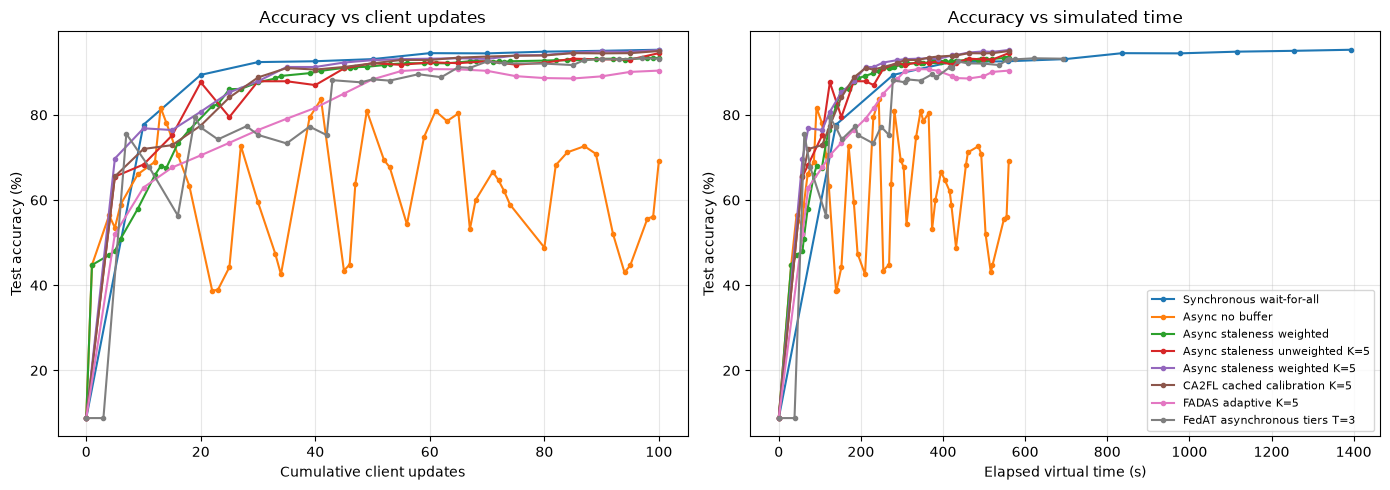

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for r in runs:
    df = curves[r]
    axes[0].plot(df["updates"], df["accuracy"] * 100, marker="o", markersize=3, label=labels[r])
    axes[1].plot(df["time"], df["accuracy"] * 100, marker="o", markersize=3, label=labels[r])
axes[0].set(xlabel="Cumulative client updates", ylabel="Test accuracy (%)", title="Accuracy vs client updates")
axes[1].set(xlabel="Elapsed virtual time (s)", ylabel="Test accuracy (%)", title="Accuracy vs simulated time")
for ax in axes:
    ax.grid(alpha=.3)
axes[1].legend(loc="best", fontsize=8)
plt.tight_layout()
fig.savefig(RESULTS / "comparison_accuracy_vs_updates_and_time.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Test loss

> **Note:** spikes mean the global model is being pushed around, usually by stale or strongly non-IID updates. A smooth, falling curve means stable training.

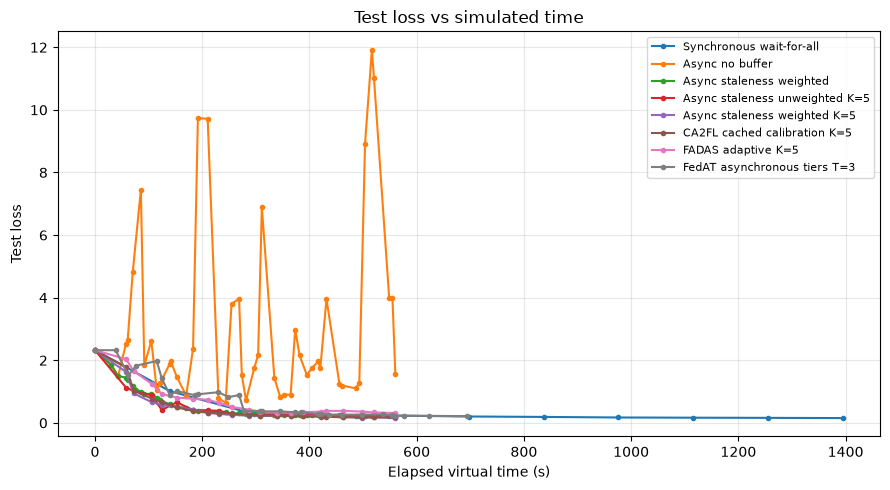

In [5]:
fig = plt.figure(figsize=(9, 5))
for r in runs:
    plt.plot(curves[r]["time"], curves[r]["loss"], marker="o", markersize=3, label=labels[r])
plt.xlabel("Elapsed virtual time (s)"); plt.ylabel("Test loss"); plt.title("Test loss vs simulated time")
plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout()
fig.savefig(RESULTS / "comparison_test_loss_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Throughput

Cumulative client updates received per virtual second.

> **Note:** synchronous FL is low because every round waits for the slowest client. High throughput only helps if the updates are still useful, so read this together with the accuracy plot.

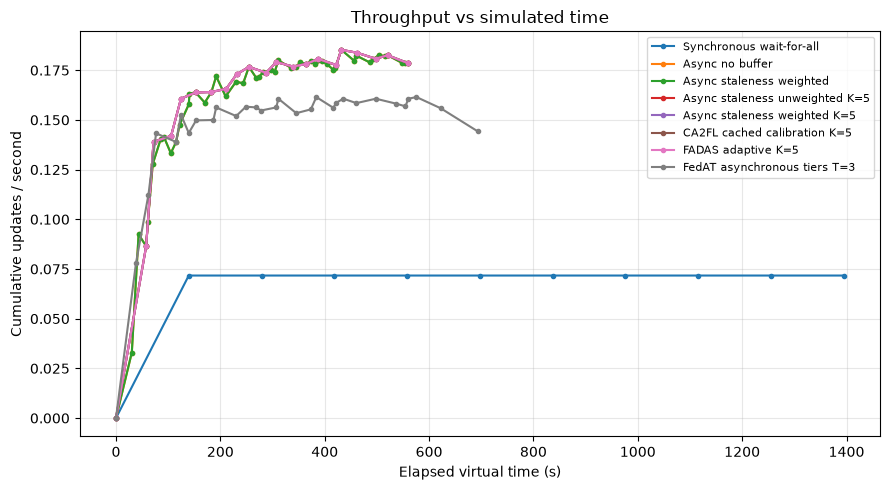

In [6]:
fig = plt.figure(figsize=(9, 5))
for r in runs:
    plt.plot(curves[r]["time"], curves[r]["throughput"], marker="o", markersize=3, label=labels[r])
plt.xlabel("Elapsed virtual time (s)"); plt.ylabel("Cumulative updates / second"); plt.title("Throughput vs simulated time")
plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout()
fig.savefig(RESULTS / "comparison_throughput_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Additional metrics

These go beyond the original comparison and cover the other research goals: fairness, stragglers and staleness. They use the same plot style and are saved as `comparison_*.png` too.

| Column | Meaning | Better |
|---|---|---|
| `worst10_clients_acc_pct` | accuracy on the 10% of clients the model serves worst (fairness across non-IID data) | higher |
| `time_to_80pct` / `time_to_90pct` | virtual seconds to first reach that accuracy (seeds that reached it / all seeds) | lower |
| `mean_staleness` | how many versions old an update is when it arrives | lower |
| `participation_fairness` | Jain index of how evenly clients contributed updates (1 = perfectly even) | higher |

In [7]:
def extra_row(r):
    g, u = metrics[metrics.run == r], updates[updates.run == r]
    row = {"approach": labels[r], "worst10_clients_acc_pct": round(100 * float(curves[r].worst10_client_acc.iloc[-1]), 2)}
    for t in (0.80, 0.90):
        hits = [s.loc[s.accuracy >= t, "time"].min() for _, s in g.groupby("seed")]
        hits = [h for h in hits if pd.notna(h)]
        row[f"time_to_{int(t * 100)}pct"] = f"{np.mean(hits):.0f} ({len(hits)}/{g.seed.nunique()})" if hits else "never"
    row["mean_staleness"] = round(float(u.staleness.mean()), 2) if len(u) else None
    n, jain = int(g.num_clients.iloc[0]), []
    for _, us in u.groupby("seed"):
        c = np.bincount(us.client, minlength=n).astype(float)
        jain.append(c.sum() ** 2 / (n * (c ** 2).sum()))
    row["participation_fairness"] = round(float(np.mean(jain)), 3) if jain else None
    return row


extra = pd.DataFrame([extra_row(r) for r in runs])
extra.to_csv(RESULTS / "comparison_additional_metrics.csv", index=False)
display(extra)

,approach,worst10_clients_acc_pct,time_to_80pct,time_to_90pct,mean_staleness,participation_fairness
0,Synchronous wait-for-all,94.20,279 (1/1),418 (1/1),0.00,1.000
1,Async no buffer,58.03,92 (1/1),never,8.30,0.862
2,Async staleness weighted,92.21,139 (1/1),244 (1/1),8.30,0.862
3,Async staleness unweighted K=5,93.40,124 (1/1),255 (1/1),1.62,0.862
4,Async staleness weighted K=5,94.73,124 (1/1),211 (1/1),1.62,0.862
5,CA2FL cached calibration K=5,93.88,153 (1/1),211 (1/1),1.62,0.862
6,FADAS adaptive K=5,87.81,231 (1/1),307 (1/1),1.62,0.862
7,FedAT asynchronous tiers T=3,92.05,278 (1/1),416 (1/1),1.62,0.870


### Fairness: worst-10% clients

The global model is scored on each client's own data mix; the curve is the accuracy of the worst-served 10% of clients.

> **Note:** a high average accuracy can hide clients that are served badly, usually those with unusual data or slow devices. A good method keeps this curve close to the overall accuracy.

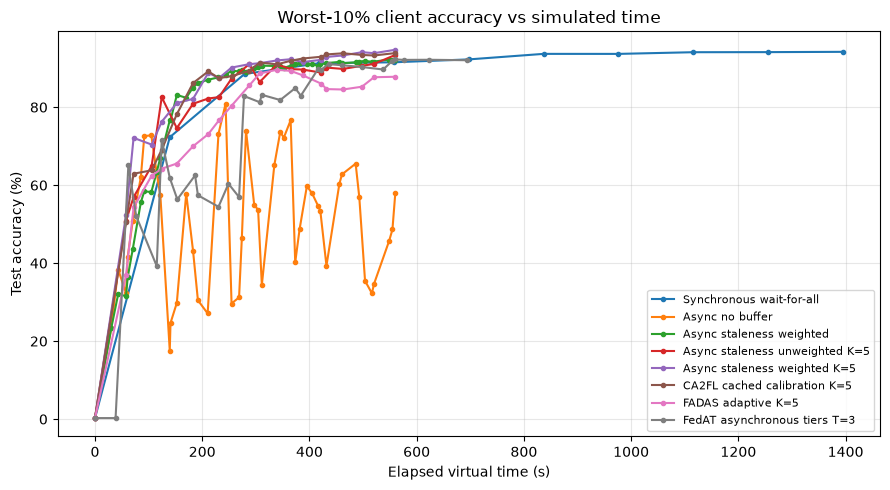

In [8]:
fig = plt.figure(figsize=(9, 5))
for r in runs:
    plt.plot(curves[r]["time"], curves[r]["worst10_client_acc"] * 100, marker="o", markersize=3, label=labels[r])
plt.xlabel("Elapsed virtual time (s)"); plt.ylabel("Test accuracy (%)"); plt.title("Worst-10% client accuracy vs simulated time")
plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout()
fig.savefig(RESULTS / "comparison_fairness_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

### Staleness and client participation

* **Left:** how stale each update was when it arrived. The box shows the spread; points are outliers, usually the stragglers.
* **Right:** share of all received updates per client, with each client's speed (batches per virtual second) under its label.

> **Note:** in asynchronous FL, fast clients send many more updates, so the model drifts toward their data. Even bars mean every client was heard equally.

/tmp/ipykernel_24371/101429763.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot([updates.loc[updates.run == r, "staleness"] for r in runs], vert=False)


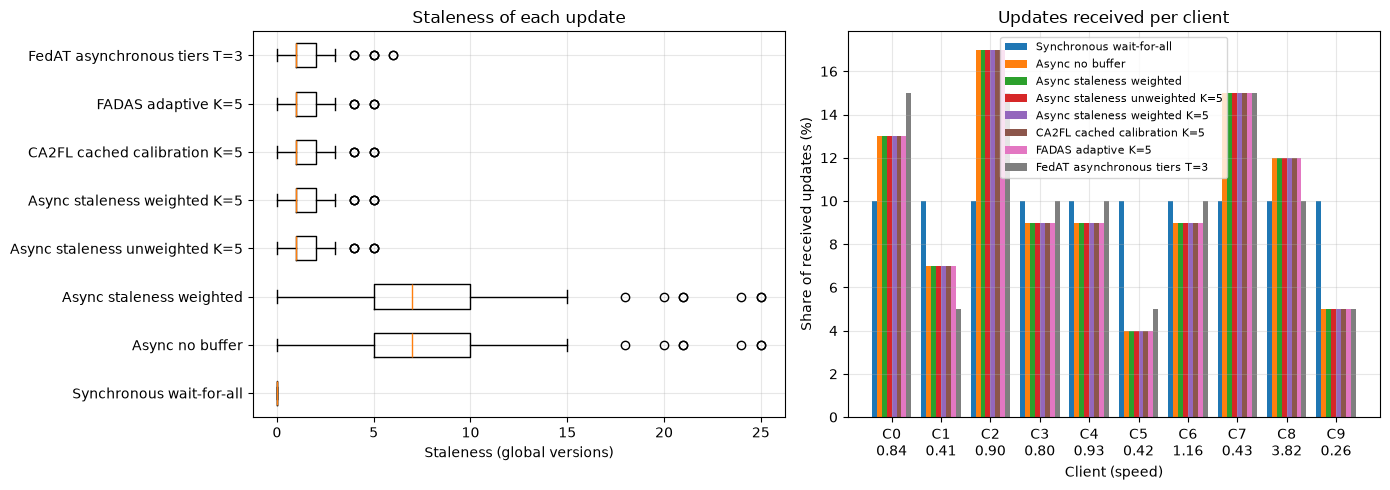

In [9]:
speeds, _, _ = make_devices(load_settings(), int(metrics.seed.iloc[0]))
share = (updates.groupby(["run", "client"]).size() / updates.groupby("run").size()).unstack(fill_value=0)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([updates.loc[updates.run == r, "staleness"] for r in runs], vert=False)
axes[0].set_yticks(range(1, len(runs) + 1), [labels[r] for r in runs])
axes[0].set(xlabel="Staleness (global versions)", title="Staleness of each update")
width = 0.8 / len(runs)
for i, r in enumerate(runs):
    axes[1].bar(np.arange(share.shape[1]) + i * width, share.loc[r] * 100, width, color=colors[i % len(colors)], label=labels[r])
axes[1].set_xticks(np.arange(share.shape[1]) + 0.4 - width / 2,
                   [f"C{c}\n{speeds[c]:.2f}" if c < len(speeds) else f"C{c}" for c in share.columns])
axes[1].set(xlabel="Client (speed)", ylabel="Share of received updates (%)", title="Updates received per client")
axes[1].legend(loc="best", fontsize=8)
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout()
fig.savefig(RESULTS / "comparison_staleness_and_participation.png", dpi=150, bbox_inches="tight")
plt.show()